# Segment-aware EV energy-estimation chat

This notebook visualizes and tests the new `energy_consumption_kwh` ReAct tool and its internal LangGraph subgraph. The subgraph fetches a fresh Valhalla route, Open-Meteo weather, and SUMO vehicle state for every estimate.

```mermaid
flowchart TD
    D[Driver question] --> A[ReAct assistant]
    A -->|selects energy_consumption_kwh| T[ToolNode]
    T --> E[Energy tool]
    E --> F[Fetch fresh route + weather + vehicle]
    F --> S[Validate route segments]
    S --> L[Apply Tunisian speed limits]
    L --> M[Prepare 15 ML features internally]
    M --> P[Predict each segment]
    P --> G[Aggregate estimated kWh]
    G --> B[Compare with available battery + reserve]
    B --> C[Compact result only]
    C --> A
    A --> R[Driver answer]
```

Only the compact energy and battery comparison returns to the assistant. Route payloads, weather, telemetry, segments, and ML feature vectors remain private inside the subgraph.

Current Valhalla output does not provide an average road-grade value compatible with the trained model, and it does not predict future acceleration. The test prompts therefore **explicitly authorize** a 0% average-slope assumption and 0 m/s² segment-average acceleration (steady speed). Remove those assumptions to verify the tool returns a clear limitation instead of inventing values.

In [1]:
from pathlib import Path
import json
import sys
from uuid import uuid4

from dotenv import load_dotenv
from IPython.display import Image, JSON, Markdown, display
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'agent').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

load_dotenv(PROJECT_ROOT / '.env')
print('Project root:', PROJECT_ROOT)

Project root: c:\Users\Yessine\Desktop\vehicle_ai_copilote


## 1. Start the fresh SUMO vehicle source

Keep `USE_GUI = False` for a quick test. Change it to `True` only when you also want to watch the vehicle.

In [2]:
from simulation.trip_simulator import TripSimulator
import traci

# Close a leftover default TraCI connection when this cell is rerun.
if traci.isLoaded():
    traci.close(False)

USE_GUI = False
simulator = TripSimulator(
    origin='Route El Ain, central Sfax',
    destination='North-east central Sfax',
    traffic_level='normal',
    initial_soc_percent=80.0,
    ambient_temperature_c=25.0,
)
initial_state = simulator.start(use_gui=USE_GUI)
print('SUMO status:', initial_state['status'])
print('Battery SOC:', initial_state['ev']['battery_soc_percent'], '%')
print('Available energy:', initial_state['ev']['battery_energy_kwh'], 'kWh')

SUMO status: running
Battery SOC: 80.0 %
Available energy: 33.76 kWh


## 2. Build and visualize the internal energy subgraph

## Energy-Estimation Subgraph

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	fetch_fresh_context(fetch_fresh_context)
	segment_route(segment_route)
	apply_speed_limits(apply_speed_limits)
	prepare_features(prepare_features)
	predict_segments(predict_segments)
	aggregate_energy(aggregate_energy)
	check_feasibility(check_feasibility)
	__end__([<p>__end__</p>]):::last
	__start__ --> fetch_fresh_context;
	aggregate_energy --> check_feasibility;
	apply_speed_limits --> prepare_features;
	fetch_fresh_context --> segment_route;
	predict_segments --> aggregate_energy;
	prepare_features --> predict_segments;
	segment_route --> apply_speed_limits;
	check_feasibility --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

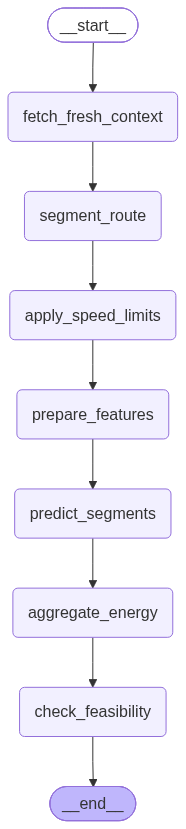

In [3]:
from simulation.energy_estimation import (
    build_energy_estimation_graph,
    energy_result,
)

energy_graph = build_energy_estimation_graph(simulator)
energy_workflow = energy_graph.get_graph()
display(Markdown('## Energy-Estimation Subgraph'))
display(Markdown(f'```mermaid\n{energy_workflow.draw_mermaid()}\n```'))

# PNG rendering is optional; Mermaid text above works without it.
try:
    display(Image(energy_workflow.draw_mermaid_png()))
except Exception as error:
    print('PNG rendering unavailable:', error)

## 3. Direct subgraph test (no LLM)

This cell proves the calculation graph itself works before testing LLM tool selection. It calls live route/weather APIs and the saved ML pipeline.

In [4]:
direct_state = energy_graph.invoke({
    'origin': 'Sfax',
    'destination': 'Tunis',
    'reserve_soc_percent': 15.0,
    'assumed_slope_percent': 0.0,
    'assumed_acceleration_mps2': 0.0,
    'warnings': [],
    'errors': [],
})
direct_result = energy_result(direct_state)
print('Internal subgraph keys:', sorted(direct_state.keys()))
print('Compact LLM-facing keys:', sorted(direct_result.keys()))
display(JSON(direct_result, expanded=False))

Internal subgraph keys: ['assumed_acceleration_mps2', 'assumed_slope_percent', 'available_energy_kwh', 'destination', 'energy_after_trip_kwh', 'energy_available_after_reserve_kwh', 'errors', 'feasible', 'origin', 'projected_arrival_soc_percent', 'reserve_energy_kwh', 'reserve_soc_percent', 'route', 'route_segments', 'total_distance_km', 'total_predicted_energy_kwh', 'vehicle', 'warnings', 'weather']
Compact LLM-facing keys: ['additional_warning_count', 'available_energy_kwh', 'destination', 'energy_after_trip_kwh', 'energy_available_after_reserve_kwh', 'estimated_energy_consumption_kwh', 'feasible', 'origin', 'projected_arrival_soc_percent', 'reserve_energy_kwh', 'reserve_soc_percent', 'status', 'total_distance_km', 'warnings']


<IPython.core.display.JSON object>

## 4. Build the existing ReAct copilot

The main graph remains `assistant → ToolNode → assistant`. The LLM-facing `energy_consumption_kwh` tool invokes the separate subgraph visualized above.

Thread: energy-estimation-e8a42271-8b3d-4998-b12f-92e54a2e22d6
Available tools: weather_tool, route_tool, vehicle_tool, energy_consumption_kwh


## Overall ReAct Copilot Graph

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	assistant(assistant)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> assistant;
	assistant -.-> __end__;
	assistant -.-> tools;
	tools --> assistant;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

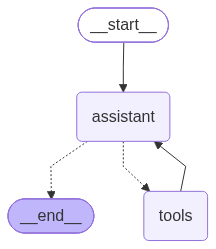

In [5]:
from agent.graph import build_copilot_graph

copilot = build_copilot_graph(simulator)
THREAD_ID = f'energy-estimation-{uuid4()}'
print('Thread:', THREAD_ID)
print('Available tools: weather_tool, route_tool, vehicle_tool, energy_consumption_kwh')
overall_workflow = copilot.get_graph(xray=True)
display(Markdown('## Overall ReAct Copilot Graph'))
display(Markdown(f'```mermaid\n{overall_workflow.draw_mermaid()}\n```'))

try:
    display(Image(overall_workflow.draw_mermaid_png()))
except Exception as error:
    print('PNG rendering unavailable:', error)

In [6]:
def ask_copilot(question: str):
    """Stream only the tools selected by the LLM, their outputs, and the final answer."""
    display(Markdown(f'**Driver:** {question}'))
    config = {'configurable': {'thread_id': THREAD_ID}}
    final_message = None

    try:
        for update in copilot.stream(
            {'messages': [HumanMessage(content=question)]},
            config=config,
            stream_mode='updates',
        ):
            for node_name, payload in update.items():
                for message in payload.get('messages', []):
                    if isinstance(message, AIMessage) and message.tool_calls:
                        for call in message.tool_calls:
                            print(f"\n[Tool called] {call['name']}")
                            print(f"Arguments: {call.get('args', {})}")
                    elif isinstance(message, ToolMessage):
                        print(f'[Tool output] {message.name}')
                        try:
                            tool_content = (
                                json.loads(message.content)
                                if isinstance(message.content, str)
                                else message.content
                            )
                            display(JSON(tool_content, expanded=False))
                        except (TypeError, ValueError):
                            print(message.content)
                    elif node_name == 'assistant' and isinstance(message, AIMessage):
                        if message.content:
                            final_message = message
    except Exception as error:
        print(f'\n[Error] {type(error).__name__}: {error}')
        raise

    if final_message is not None:
        display(Markdown('**Copilot:**\n\n' + str(final_message.content)))
    return final_message


# Put each test prompt directly inside ask_copilot(...).

## 5. Direct energy-chat prompts

Each test cell contains its complete prompt directly inside `ask_copilot(...)`.

In [7]:
ask_copilot(
    'How many kWh will the trip from Sfax city centre to Tunis city centre consume?'
)

**Driver:** How many kWh will the trip from Sfax city centre to Tunis city centre consume?


[Tool called] energy_consumption_kwh
Arguments: {'destination': 'Tunis city centre', 'origin': 'Sfax city centre'}
[Tool output] energy_consumption_kwh


<IPython.core.display.JSON object>

**Copilot:**

The estimated energy consumption for the trip from **Sfax city centre** to **Tunis city centre** is **≈ 57.5 kWh**.

AIMessage(content='The estimated energy consumption for the trip from **Sfax city centre** to **Tunis city centre** is **≈\u202f57.5\u202fkWh**.', additional_kwargs={'reasoning_content': 'We need to answer: "How many kWh will the trip from Sfax city centre to Tunis city centre consume?" Use the energy_consumption_kwh result. Provide the estimated energy consumption: 57.545 kWh. Also note that battery insufficient, but question only asks consumption. Provide answer succinctly.'}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 2145, 'total_tokens': 2251, 'completion_time': 0.221661781, 'completion_tokens_details': {'reasoning_tokens': 64}, 'prompt_time': 0.104005695, 'prompt_tokens_details': None, 'queue_time': 0.211503078, 'total_time': 0.325667476}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'reasoning_effort': 'medium', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='

In [8]:
# Main mixed urban/highway energy-sufficiency test.
ask_copilot(
    'Can my EV travel from Sfax city centre to Tunis city centre with a 15% battery reserve?'
)

**Driver:** Can my EV travel from Sfax city centre to Tunis city centre with a 15% battery reserve?


[Tool called] energy_consumption_kwh
Arguments: {'destination': 'Tunis city centre', 'origin': 'Sfax city centre', 'reserve_soc_percent': 15}
[Tool output] energy_consumption_kwh


<IPython.core.display.JSON object>

**Copilot:**

**No – the trip is not feasible with a 15 % reserve.**

- **Estimated energy needed:** ≈ 57.5 kWh  
- **Energy currently available in the battery:** ≈ 33.8 kWh  
- **Reserve (15 % of SOC):** ≈ 6.3 kWh, leaving only about 27.4 kWh usable for the drive.  

After accounting for the reserve, you would be short by roughly **30 kWh** (the model predicts a negative energy balance of –23.8 kWh and a projected arrival SOC of 0 %).  

**What to do:**  
- Charge the vehicle before departing, or  
- Reduce the trip distance (e.g., stop part‑way to charge), or  
- Increase the allowed reserve (though that would further reduce usable energy).

In short, with the current state of charge and a 15 % reserve, you cannot complete the Sfax → Tunis journey without recharging.

AIMessage(content='**No – the trip is not feasible with a 15\u202f% reserve.**\n\n- **Estimated energy needed:**\u202f≈\u202f57.5\u202fkWh  \n- **Energy currently available in the battery:**\u202f≈\u202f33.8\u202fkWh  \n- **Reserve (15\u202f% of SOC):**\u202f≈\u202f6.3\u202fkWh, leaving only about\u202f27.4\u202fkWh usable for the drive.  \n\nAfter accounting for the reserve, you would be short by roughly **30\u202fkWh** (the model predicts a negative energy balance of –23.8\u202fkWh and a projected arrival SOC of 0\u202f%).  \n\n**What to do:**  \n- Charge the vehicle before departing, or  \n- Reduce the trip distance (e.g., stop part‑way to charge), or  \n- Increase the allowed reserve (though that would further reduce usable energy).\n\nIn short, with the current state of charge and a 15\u202f% reserve, you cannot complete the Sfax\u202f→\u202fTunis journey without recharging.', additional_kwargs={'reasoning_content': 'We need to answer: "Can my EV travel from Sfax city centre to Tu

In [9]:
# Advance SUMO, then prove a follow-up performs a fresh calculation.
simulator.step(60)
ask_copilot(
    'Recalculate whether my battery is still sufficient to reach Tunis city centre. '
    'Fetch every live input again.'
)

**Driver:** Recalculate whether my battery is still sufficient to reach Tunis city centre. Fetch every live input again.


[Tool called] energy_consumption_kwh
Arguments: {'destination': 'Tunis city centre', 'origin': 'Sfax city centre', 'reserve_soc_percent': 15}
[Tool output] energy_consumption_kwh


<IPython.core.display.JSON object>

**Copilot:**

**Result (fresh calculation):**

- **Trip distance:** 266.6 km  
- **Estimated energy needed:** 57.55 kWh  
- **Energy currently available in the battery:** 33.69 kWh  
- **Reserve (15 % of SOC):** 6.33 kWh → usable energy after reserve = 27.36 kWh  

**Feasibility:** **Not feasible** – after accounting for the 15 % reserve you would be short by about **23.9 kWh** (projected arrival SOC = 0 %).  

**What to do:** Charge the vehicle (or add a charging stop) before attempting the Sfax → Tunis leg, or increase the allowed reserve only if you can still meet the required energy (which you cannot with the current state).

AIMessage(content='**Result (fresh calculation):**\n\n- **Trip distance:**\u202f266.6\u202fkm  \n- **Estimated energy needed:**\u202f57.55\u202fkWh  \n- **Energy currently available in the battery:**\u202f33.69\u202fkWh  \n- **Reserve (15\u202f% of SOC):**\u202f6.33\u202fkWh → usable energy after reserve\u202f=\u202f27.36\u202fkWh  \n\n**Feasibility:** **Not feasible** – after accounting for the 15\u202f% reserve you would be short by about **23.9\u202fkWh** (projected arrival SOC\u202f=\u202f0\u202f%).  \n\n**What to do:** Charge the vehicle (or add a charging stop) before attempting the Sfax\u202f→\u202fTunis leg, or increase the allowed reserve only if you can still meet the required energy (which you cannot with the current state).', additional_kwargs={'reasoning_content': 'We need to answer the user\'s request: "Recalculate whether my battery is still sufficient to reach Tunis city centre. Fetch every live input again."\n\nWe have just fetched energy_consumption_kwh with fresh dat

## 6. Sfax location-resolver verification

The first cell tests the trusted aliases directly. The following cells contain complete `ask_copilot(...)` calls. Their streamed output shows only the tool selected by the LLM, its arguments, its result, and the final answer.

Expected sequence: `[Tool called]` → `Arguments` → `[Tool output]` → `Copilot`.

In [10]:
from location.resolver import LocationResolutionError, LocationResolver

resolver = LocationResolver()
SFAX_RESOLVER_CASES = {
    'origin': 'Route El Ain Km 4, Sfax',
    'destination': "ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax",
}

resolved_sfax_locations = {}
for label, location_name in SFAX_RESOLVER_CASES.items():
    try:
        resolved = resolver.resolve(location_name)
        resolved_sfax_locations[label] = resolved
        print(f'[PASS] {label}: {location_name}')
        print(f'       canonical: {resolved.canonical_name}')
        print(f'       coordinates: {resolved.latitude:.7f}, {resolved.longitude:.7f}')
        print(f'       source: {resolved.source}; confidence: {resolved.confidence}')
    except LocationResolutionError as error:
        print(f'[FAIL] {label}: {location_name}')
        print(f'       {type(error).__name__}: {error}')

resolver_ok = (
    len(resolved_sfax_locations) == len(SFAX_RESOLVER_CASES)
    and all(item.source == 'trusted_location' for item in resolved_sfax_locations.values())
)
print('\nResolver check:', 'PASS' if resolver_ok else 'FAIL')

[PASS] origin: Route El Ain Km 4, Sfax
       canonical: Route El Ain Km 4, Sfax, Tunisia
       coordinates: 34.7518952, 10.7296079
       source: trusted_location; confidence: 1.0
[PASS] destination: ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax
       canonical: ENET'Com, Technopole de Sfax, Sakiet Ezzit, Tunisia
       coordinates: 34.8396200, 10.7566620
       source: trusted_location; confidence: 1.0

Resolver check: PASS


In [11]:
# Expected first tool: route_tool
ask_copilot(
    "Get the driving route from Route El Ain Km 4, Sfax to "
    "ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax. "
    "Report the resolved origin and destination, driving distance, and estimated travel time and weather."
)

**Driver:** Get the driving route from Route El Ain Km 4, Sfax to ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax. Report the resolved origin and destination, driving distance, and estimated travel time and weather.


[Tool called] route_tool
Arguments: {'destination': "ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax", 'origin': 'Route El Ain Km 4, Sfax'}
[Tool output] route_tool


<IPython.core.display.JSON object>


[Tool called] weather_tool
Arguments: {'city': 'Sakiet Ezzit, Tunisia'}
[Tool output] weather_tool


<IPython.core.display.JSON object>


[Tool called] weather_tool
Arguments: {'city': 'Sfax, Tunisia'}
[Tool output] weather_tool


<IPython.core.display.JSON object>

**Copilot:**

**Resolved locations**  
- **Origin:** Route El Ain Km 4, Sfax, Tunisia  
- **Destination:** ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax, Tunisia  

**Driving route**  
- **Distance:** ≈ 12.2 km  
- **Estimated travel time:** ≈ 23 minutes  

**Current weather at the destination area (Sfax)**  
- Temperature: 20 °C  
- Humidity: 47 %  
- Wind: 5.9 km/h from the north‑east (light breeze)  
- Conditions: Mainly clear, no precipitation, good visibility (≈ 42 km)  

So, the trip from Route El Ain Km 4 to ENET'Com in Sakiet Ezzit is a short 12‑km urban/suburban drive taking about 23 minutes, and the weather is clear and mild.

AIMessage(content="**Resolved locations**  \n- **Origin:** Route\u202fEl\u202fAin\u202fKm\u202f4,\u202fSfax,\u202fTunisia  \n- **Destination:** ENET'Com,\u202fCite\u202fEl\u202fOns,\u202fSakiet\u202fEzzit,\u202fSfax,\u202fTunisia  \n\n**Driving route**  \n- **Distance:**\u202f≈\u202f12.2\u202fkm  \n- **Estimated travel time:**\u202f≈\u202f23\u202fminutes  \n\n**Current weather at the destination area (Sfax)**  \n- Temperature:\u202f20\u202f°C  \n- Humidity:\u202f47\u202f%  \n- Wind:\u202f5.9\u202fkm/h from the north‑east (light breeze)  \n- Conditions:\u202fMainly clear, no precipitation, good visibility (≈\u202f42\u202fkm)  \n\nSo, the trip from Route\u202fEl\u202fAin\u202fKm\u202f4 to ENET'Com in Sakiet\u202fEzzit is a short 12‑km urban/suburban drive taking about 23\u202fminutes, and the weather is clear and mild.", additional_kwargs={'reasoning_content': 'We need to answer: Provide resolved origin and destination, driving distance, estimated travel time, and weather. Use the route_

In [12]:
# Test the route-energy tool, then inspect its fresh SUMO traffic input and model features.
ask_copilot(
    "Estimate the energy required to drive from Route El Ain Km 4, Sfax to "
    "ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax. "
    "Report the resolved places, route distance, and estimated energy."
)

# Invoke the subgraph directly to inspect internal inputs (the LLM-facing
# tool response remains compact and does not include these segment details).
import pandas as pd
from copy import deepcopy
from simulation.energy_estimation import (
    CATEGORICAL_FEATURES,
    FEATURES,
    build_ml_features,
)

feature_debug_state = energy_graph.invoke({
    'origin': 'Route El Ain Km 4, Sfax',
    'destination': "ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax",
    'reserve_soc_percent': 15.0,
    'warnings': [],
    'errors': [],
})

if feature_debug_state.get('errors'):
    print('Energy subgraph error:')
    for error in feature_debug_state['errors']:
        print('-', error)
else:
    segments = feature_debug_state['route_segments']
    model_input_rows = [
        {
            'segment_id': segment['segment_id'],
            'road_type': segment['road_type'],
            **segment['ml_features'],
            'predicted_energy_kwh': segment['predicted_energy_kwh'],
        }
        for segment in segments
    ]
    model_inputs_df = pd.DataFrame(
        model_input_rows,
        columns=['segment_id', 'road_type', *FEATURES, 'predicted_energy_kwh'],
    )
    display(Markdown('### Exact per-segment inputs sent to the ML model'))
    display(model_inputs_df.round(3))
    print('Feature count:', len(FEATURES))
    print('Feature order:', FEATURES)
    print('Normalized fresh vehicle traffic state:', feature_debug_state['vehicle'].get('traffic'))
    print(
        'Traffic category used for prediction:',
        segments[0]['ml_features']['traffic_condition'],
    )

    # Probe all supported normalized traffic levels through the production feature builder.
    first_segment = segments[0]
    fresh_vehicle = feature_debug_state['vehicle']
    traffic_cases = [('low', '0'), ('normal', '1'), ('heavy', '2'), (None, '1')]
    traffic_rows = []
    for level, expected_code in traffic_cases:
        probe_vehicle = deepcopy(fresh_vehicle)
        probe_traffic = probe_vehicle.get('traffic')
        if not isinstance(probe_traffic, dict):
            probe_traffic = {}
            probe_vehicle['traffic'] = probe_traffic
        if level is None:
            probe_traffic.pop('level', None)
            case_name = 'missing (defaults to normal)'
        else:
            probe_traffic['level'] = level
            case_name = level
        probe_features = build_ml_features(
            vehicle=probe_vehicle,
            weather=feature_debug_state['weather'],
            segment=first_segment,
        )
        traffic_rows.append({
            'vehicle traffic.level': case_name,
            'model traffic_condition': probe_features['traffic_condition'],
            'expected': expected_code,
            'status': 'OK' if probe_features['traffic_condition'] == expected_code else 'CHECK',
        })
    display(Markdown('### Fresh vehicle traffic mapping check'))
    display(pd.DataFrame(traffic_rows))

    # Check feature types and broad plausibility bounds for this trip.
    numeric_ranges = {
        'motor_power_kW': (1, 300),
        'vehicle_weight_kg': (500, 5000),
        'drag_coefficient_Cd': (0.1, 1.0),
        'frontal_area_m2': (0.5, 5.0),
        'rolling_resistance_Cr': (0.001, 0.1),
        'motor_efficiency_pct': (1, 100),
        'avg_driving_speed_kmh': (0, 150),
        'ambient_temperature_C': (-30, 60),
        'passengers': (1, 8),
        'battery_age_years': (0, 30),
        'tyre_pressure_deviation_psi': (-10, 10),
    }
    allowed_categories = {
        'ac_usage': {'0', '1'},
        'terrain_type': {'0', '1', '2'},
        'traffic_condition': {'0', '1', '2'},
        'driving_style': {'0', '1', '2'},
    }
    validation_rows = []
    for name in FEATURES:
        values = model_inputs_df[name]
        if name in CATEGORICAL_FEATURES:
            valid = values.map(lambda value: isinstance(value, str) and value in allowed_categories[name]).all()
            observed = ', '.join(sorted(set(values)))
            expected = ', '.join(sorted(allowed_categories[name]))
        else:
            numeric_values = pd.to_numeric(values, errors='coerce')
            lower, upper = numeric_ranges[name]
            valid = numeric_values.notna().all() and numeric_values.between(lower, upper).all()
            observed = f'{numeric_values.min():.3f} to {numeric_values.max():.3f}'
            expected = f'{lower} to {upper}'
        validation_rows.append({
            'feature': name,
            'observed value/range': observed,
            'expected/check': expected,
            'status': 'OK' if valid else 'CHECK',
        })
    display(Markdown('### Feature type and plausibility checks'))
    display(pd.DataFrame(validation_rows))
    print(
        'Summed segment energy:',
        round(model_inputs_df['predicted_energy_kwh'].sum(), 3),
        'kWh',
    )

**Driver:** Estimate the energy required to drive from Route El Ain Km 4, Sfax to ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax. Report the resolved places, route distance, and estimated energy.


[Tool called] energy_consumption_kwh
Arguments: {'destination': "ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax", 'origin': 'Route El Ain Km 4, Sfax'}
[Tool output] energy_consumption_kwh


<IPython.core.display.JSON object>

**Copilot:**

**Resolved places**  
- **Origin:** Route El Ain Km 4, Sfax, Tunisia  
- **Destination:** ENET'Com, Cite El Ons, Sakiet Ezzit, Sfax, Tunisia  

**Route**  
- **Distance:** ≈ 12.2 km  

**Energy estimate**  
- **Estimated energy required for the trip:** ≈ 1.48 kWh  

The model indicates the trip is feasible with the current battery state (available energy after the 15 % reserve is about 27.4 kWh, far above the 1.48 kWh needed).

### Exact per-segment inputs sent to the ML model

,segment_id,road_type,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,avg_driving_speed_kmh,ambient_temperature_C,ac_usage,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,predicted_energy_kwh
0,1,urban,125.0,1270.0,0.29,2.38,0.012,92.0,32.0,19.8,0,0,1,1,1.0,1.0,0.07,0.006
1,2,urban,125.0,1270.0,0.29,2.38,0.012,92.0,21.0,19.8,0,0,1,1,1.0,1.0,0.07,0.008
2,3,rural,125.0,1270.0,0.29,2.38,0.012,92.0,77.0,19.8,0,0,1,1,1.0,1.0,0.07,0.044
3,4,highway,125.0,1270.0,0.29,2.38,0.012,92.0,48.0,19.8,0,0,1,1,1.0,1.0,0.07,0.035
4,5,highway,125.0,1270.0,0.29,2.38,0.012,92.0,48.0,19.8,0,0,1,1,1.0,1.0,0.07,0.044
5,6,highway,125.0,1270.0,0.29,2.38,0.012,92.0,48.0,19.8,0,0,1,1,1.0,1.0,0.07,0.340
6,7,urban,125.0,1270.0,0.29,2.38,0.012,92.0,19.0,19.8,0,0,1,1,1.0,1.0,0.07,0.032
7,8,urban,125.0,1270.0,0.29,2.38,0.012,92.0,14.0,19.8,0,0,1,1,1.0,1.0,0.07,0.007
8,9,urban,125.0,1270.0,0.29,2.38,0.012,92.0,30.1,19.8,0,0,1,1,1.0,1.0,0.07,0.679
9,10,urban,125.0,1270.0,0.29,2.38,0.012,92.0,22.0,19.8,0,0,1,1,1.0,1.0,0.07,0.003


... (2 outputs left out)

,vehicle traffic.level,model traffic_condition,expected,status
0,low,0,0,OK
1,normal,1,1,OK
2,heavy,2,2,OK
3,missing (defaults to normal),1,1,OK


### Feature type and plausibility checks

,feature,observed value/range,expected/check,status
0,motor_power_kW,125.000 to 125.000,1 to 300,OK
1,vehicle_weight_kg,1270.000 to 1270.000,500 to 5000,OK
2,drag_coefficient_Cd,0.290 to 0.290,0.1 to 1.0,OK
3,frontal_area_m2,2.380 to 2.380,0.5 to 5.0,OK
4,rolling_resistance_Cr,0.012 to 0.012,0.001 to 0.1,OK
5,motor_efficiency_pct,92.000 to 92.000,1 to 100,OK
6,avg_driving_speed_kmh,14.000 to 77.000,0 to 150,OK
7,ambient_temperature_C,19.800 to 19.800,-30 to 60,OK
8,ac_usage,0,"0, 1",OK
9,terrain_type,0,"0, 1, 2",OK


Summed segment energy: 1.481 kWh


In [13]:
# Inspect messages stored in the main copilot thread.
config = {"configurable": {"thread_id": THREAD_ID}}
saved_state = copilot.get_state(config)
saved_messages = saved_state.values.get("messages", [])

print(f"Total stored messages: {len(saved_messages)}\n")

for index, message in enumerate(saved_messages, start=1):
    print(f"{index}. {type(message).__name__}")

    # Tool calls selected by the assistant.
    tool_calls = getattr(message, "tool_calls", None)
    if tool_calls:
        for tool_call in tool_calls:
            print("   Tool call:", tool_call.get("name"))
            print("   Arguments:", tool_call.get("args"))

    # Results produced by tools.
    if isinstance(message, ToolMessage):
        print("   Tool name:", message.name)
        print("   Tool call ID:", message.tool_call_id)
        print("   Result:", message.content)

    # Human questions and final assistant answers.
    elif message.content:
        print("   Content:", message.content)

    print()

Total stored messages: 24

1. HumanMessage
   Content: How many kWh will the trip from Sfax city centre to Tunis city centre consume?

2. AIMessage
   Tool call: energy_consumption_kwh
   Arguments: {'destination': 'Tunis city centre', 'origin': 'Sfax city centre'}

3. ToolMessage
   Tool name: energy_consumption_kwh
   Tool call ID: fc_d6e9bcd3-75e6-4d8f-872b-f2b4b5ba6dae
   Result: {"status": "ok", "origin": "صفاقس, المدينة, معتمدية صفاقس المدينة, ولاية صفاقس, 3000, تونس", "destination": "تونس, ولاية تونس, تونس", "warnings": ["Weather is sampled at the destination and applied to all segments; conditions may vary along the route.", "Temporary roadworks and novice-driver restrictions are applied only when a lower posted or driver-specific limit is available.", "The configured 0.00% average slope default is used where route grade is missing.", "The configured 0.00 m/s² average acceleration default is used for segments without a driving profile (0 means steady speed).", "Segment 21 dista

## 7. Optional continuous chat

Type `quit` to stop. For a live estimate, explicitly state slope/acceleration assumptions until compatible route-grade and future driving-profile inputs are available.

In [14]:
def start_energy_chat() -> None:
    print('Energy-estimation chat ready. Type quit to stop.')
    while True:
        try:
            question = input('\nDriver: ').strip()
        except (EOFError, KeyboardInterrupt):
            print('\nChat ended.')
            break
        if question.lower() in {'quit', 'exit', 'stop'}:
            print('Chat ended.')
            break
        if question:
            ask_copilot(question)

# Uncomment when you want continuous chat:
# start_energy_chat()

In [15]:
# Run this cleanup cell when finished.
simulator.stop()
print('SUMO stopped.')

SUMO stopped.
